# 06 — Systematic Empirical Comparison Against Established Baselines
**Course:** 22AIE401 — Reinforcement Learning  
**Project:** Reinforcement Learning for Drug-Likeness Optimization of Small Molecules  
**Dataset:** ZINC-250K Held-out Test Benchmark (60 Molecules across 4 QED Tiers)  

---

## 1. Overview of Experimental Protocol
In this notebook, we systematically evaluate and compare the **Proposed Adaptive PPO Agent** against three benchmark baselines:
1. **Random Valid Edits Baseline:** Samples uniformly from chemically valid editing actions; establishes an unbiased lower-bound exploration baseline.
2. **Greedy Hill-Climbing Baseline (1-step Lookahead Oracle):** Evaluates all possible valid chemical modifications at each step and greedily selects the single edit yielding the highest immediate QED improvement.
3. **PPO Baseline (Unshaped):** A standard PPO agent trained with an unshaped reward function ($R = \Delta \text{QED} - \text{penalty}$).
4. **PPO Proposed (Adaptive):** Incorporates **Headroom- and Constraint-Slack Adaptive Reward Shaping** to balance drug-likeness gains against structural similarity and synthetic accessibility.

### Success Condition:
$$\text{Success} \iff \text{QED}_{T} \ge 0.80 \quad \text{AND} \quad \text{Tanimoto}(M_T, M_0) \ge 0.40$$


In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

benchmark_path = os.path.join(WORKSPACE_DIR, 'data', 'splits', 'test_benchmark_molecules.csv')
bench_df = pd.read_csv(benchmark_path)

print(f"Held-out Test Benchmark Cohort Size: {len(bench_df)} molecules")
print("\nDistribution across Starting-QED Groups:")
qed_dist = bench_df['qed_group'].value_counts()
for group, count in qed_dist.items():
    print(f"  {group:18s}: {count:2d} molecules")

print("\nBenchmark Summary Statistics:")
print(bench_df[['qed', 'sas']].describe().round(3).to_string())

Held-out Test Benchmark Cohort Size: 60 molecules

Distribution across Starting-QED Groups:
  Low               : 15 molecules
  Medium            : 15 molecules
  High              : 15 molecules
  Very High         : 15 molecules

Benchmark Summary Statistics:
          qed     sas
count  60.000  60.000
mean    0.681   3.033
std     0.187   0.967
min     0.268   1.964
25%     0.502   2.423
50%     0.708   2.700
75%     0.848   3.390
max     0.929   5.906


## 2. Overall Performance Comparison Matrix
We load the compiled empirical evaluation results across all 60 held-out test molecules.

In [2]:
summary_path = os.path.join(WORKSPACE_DIR, 'results', 'method_comparison_summary.csv')
summary_df = pd.read_csv(summary_path)

cols_to_show = [
    'method', 'mean_delta_qed', 'mean_nhg', 'success_rate',
    'mean_similarity', 'mean_delta_sas', 'validity_rate', 'mean_edits'
]

display_df = summary_df[cols_to_show].copy()
display_df['mean_delta_qed'] = display_df['mean_delta_qed'].map('{:+.4f}'.format)
display_df['mean_nhg'] = display_df['mean_nhg'].map('{:.3f}'.format)
display_df['success_rate'] = (display_df['success_rate'] * 100).map('{:.1f}%'.format)
display_df['mean_similarity'] = display_df['mean_similarity'].map('{:.3f}'.format)
display_df['mean_delta_sas'] = display_df['mean_delta_sas'].map('{:+.3f}'.format)
display_df['validity_rate'] = (display_df['validity_rate'] * 100).map('{:.1f}%'.format)
display_df['mean_edits'] = display_df['mean_edits'].map('{:.2f}'.format)

print("Comprehensive Benchmark Evaluation Matrix (N=60 Held-out Test Molecules):")
print(display_df.to_string(index=False))

Comprehensive Benchmark Evaluation Matrix (N=60 Held-out Test Molecules):
                 method mean_delta_qed mean_nhg success_rate mean_similarity mean_delta_sas validity_rate mean_edits
     Random Valid Edits        -0.4797   -2.560         0.0%           0.205         +2.073        100.0%       9.92
   Greedy Hill Climbing        +0.1095    0.353        56.7%           0.599         +0.400        100.0%       1.77
           PPO Baseline        -0.4376   -2.391         5.0%           0.265         +1.406        100.0%       9.60
PPO Adaptive (Proposed)        -0.1477   -0.793         5.0%           0.494         +0.723        100.0%       9.62


## 3. Comparative Visualizations across Evaluation Metrics
We generate side-by-side comparative bar charts illustrating the primary trade-offs between optimization gain ($\Delta$QED, Success Rate) and structural preservation (Tanimoto Similarity, $\Delta$SAS).

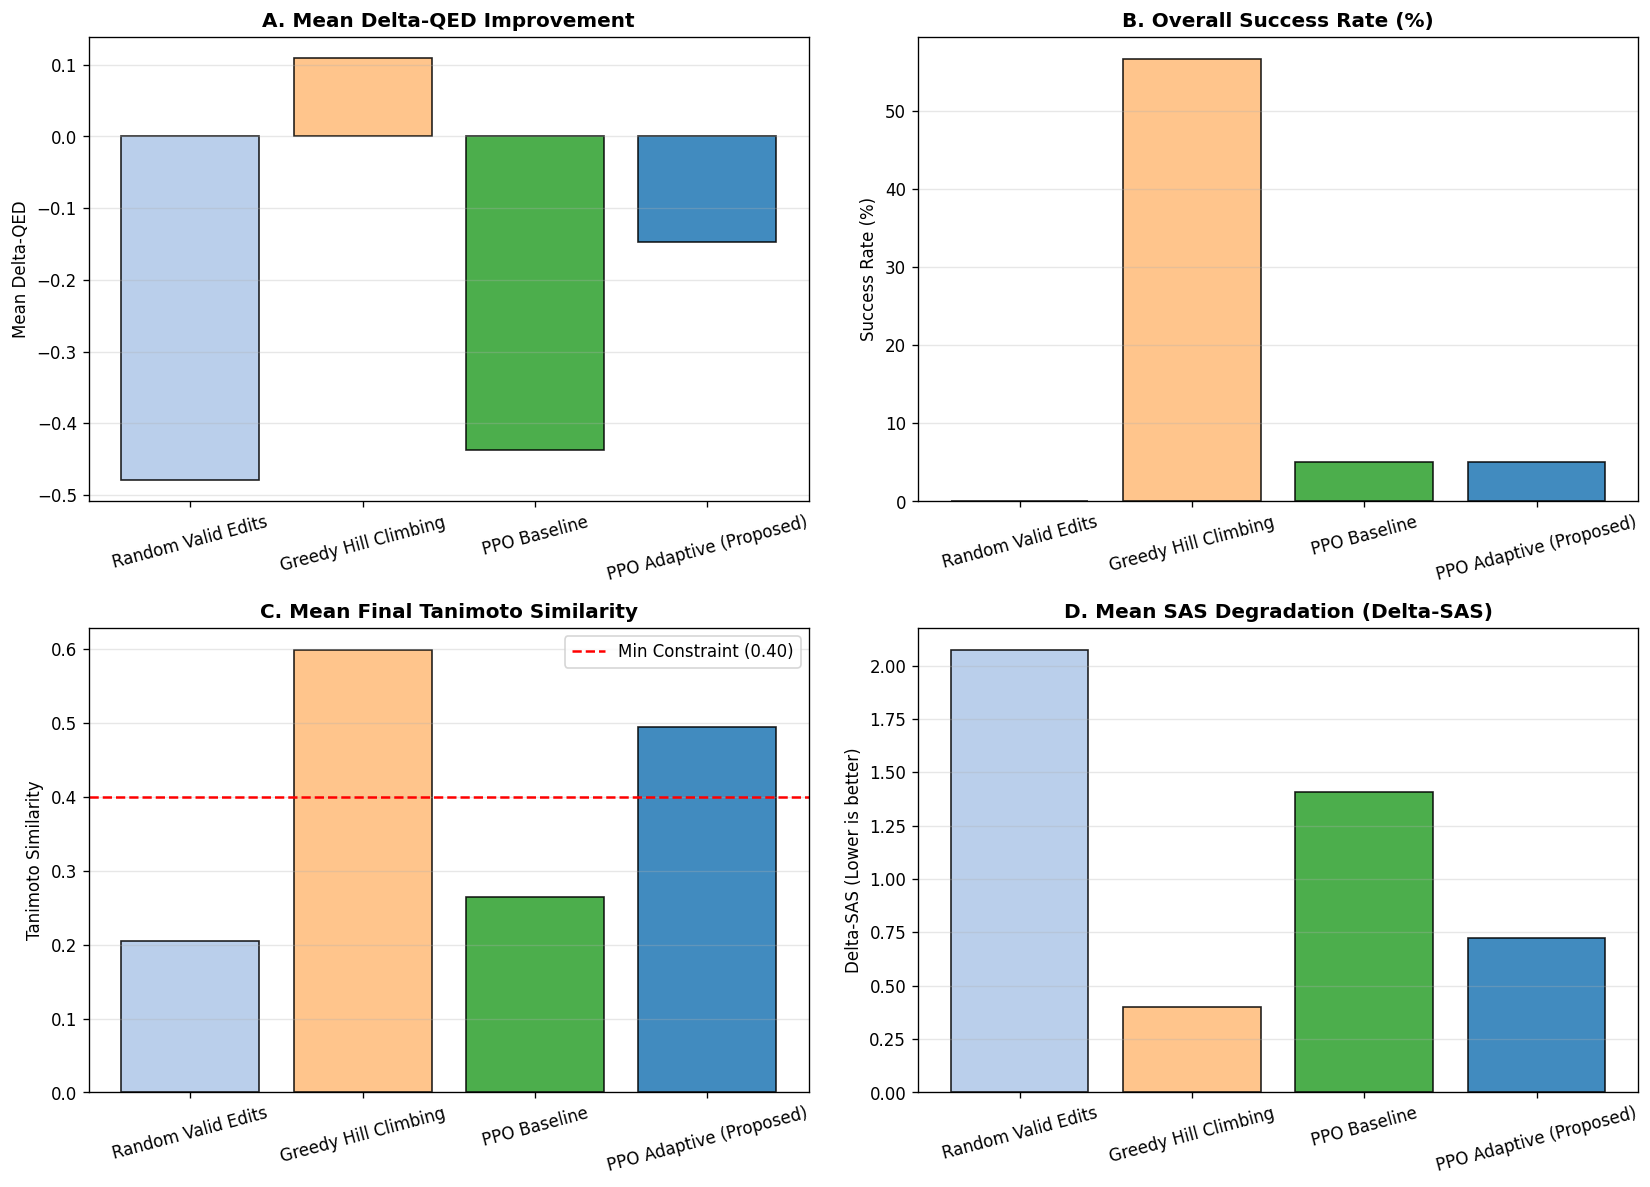

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

methods = summary_df['method']
colors = ['#aec7e8', '#ffbb78', '#2ca02c', '#1f77b4']

# 1. Delta QED
axes[0, 0].bar(methods, summary_df['mean_delta_qed'], color=colors, edgecolor='black', alpha=0.85)
axes[0, 0].set_title('A. Mean Delta-QED Improvement', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Mean Delta-QED')
axes[0, 0].grid(axis='y', alpha=0.3)
axes[0, 0].tick_params(axis='x', rotation=15)

# 2. Success Rate
axes[0, 1].bar(methods, summary_df['success_rate'] * 100, color=colors, edgecolor='black', alpha=0.85)
axes[0, 1].set_title('B. Overall Success Rate (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Success Rate (%)')
axes[0, 1].grid(axis='y', alpha=0.3)
axes[0, 1].tick_params(axis='x', rotation=15)

# 3. Tanimoto Similarity
axes[1, 0].bar(methods, summary_df['mean_similarity'], color=colors, edgecolor='black', alpha=0.85)
axes[1, 0].axhline(0.40, color='red', linestyle='--', label='Min Constraint (0.40)')
axes[1, 0].set_title('C. Mean Final Tanimoto Similarity', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Tanimoto Similarity')
axes[1, 0].grid(axis='y', alpha=0.3)
axes[1, 0].tick_params(axis='x', rotation=15)
axes[1, 0].legend()

# 4. Delta SAS
axes[1, 1].bar(methods, summary_df['mean_delta_sas'], color=colors, edgecolor='black', alpha=0.85)
axes[1, 1].set_title('D. Mean SAS Degradation (Delta-SAS)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Delta-SAS (Lower is better)')
axes[1, 1].grid(axis='y', alpha=0.3)
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 4. QED-Stratified Performance Analysis
Optimization dynamics vary drastically depending on the starting drug-likeness of the parent molecule:
- **Low QED (<0.50):** Large available headroom; high potential for dramatic multi-step improvements.
- **Medium QED (0.50-0.70):** Moderate headroom; requires balanced substitutions.
- **High QED (0.70-0.85):** Subtle modifications; higher risk of breaking similarity constraints.
- **Very High QED (>=0.85):** Little to no headroom; policy must intelligently invoke the **STOP** action to avoid degrading an already optimized molecule.

Mean Delta-QED Stratified across Tiers:
method              Greedy Hill Climbing  PPO Adaptive (Proposed)  PPO Baseline  Random Valid Edits
qed_group                                                                                          
High (0.7-0.85)                   0.0795                  -0.1461       -0.5271             -0.5777
Low (<0.5)                        0.1990                  -0.0718       -0.2520             -0.2922
Medium (0.5-0.7)                  0.1251                  -0.1669       -0.3821             -0.4381
Very High (>=0.85)                0.0420                  -0.1965       -0.5771             -0.5994

Mean Final Similarity Stratified across Tiers:
method              Greedy Hill Climbing  PPO Adaptive (Proposed)  PPO Baseline  Random Valid Edits
qed_group                                                                                          
High (0.7-0.85)                    0.578                    0.482         0.252               0.194
Low (<0.5)  

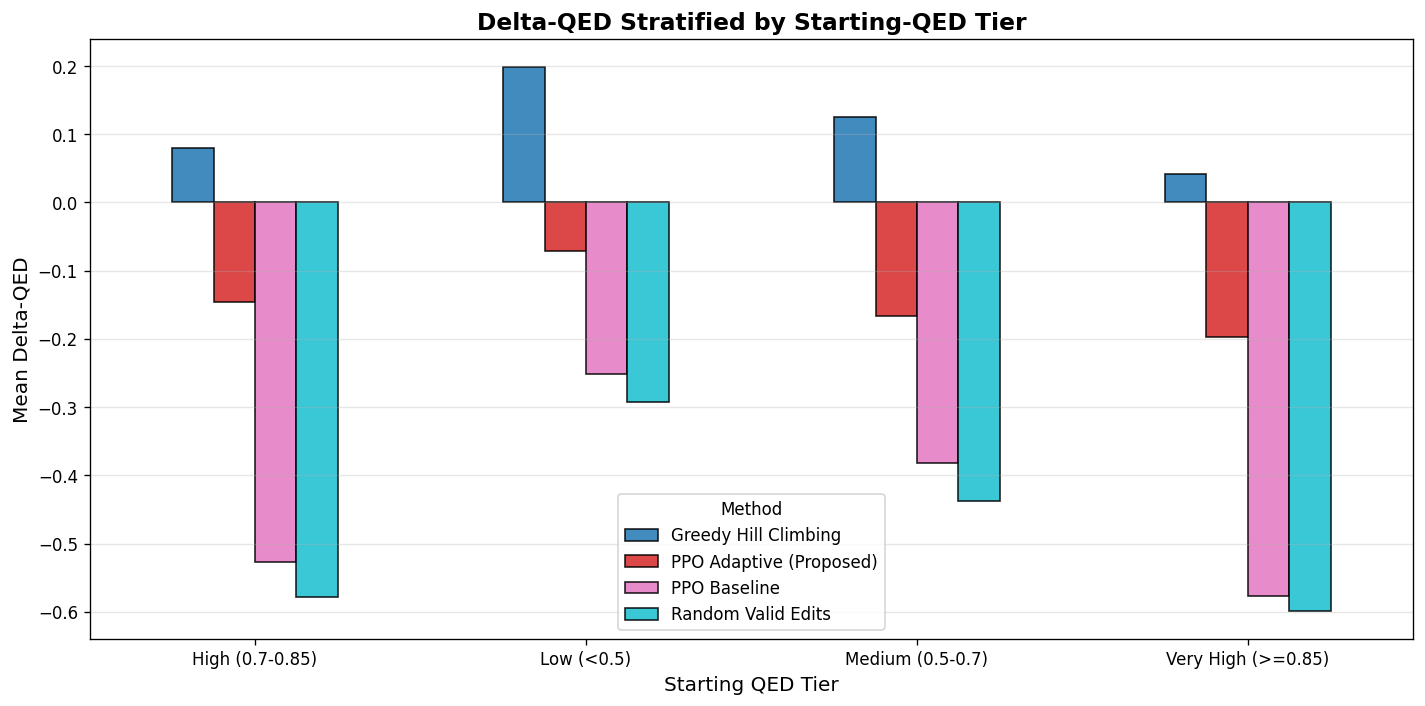

In [4]:
strat_path = os.path.join(WORKSPACE_DIR, 'results', 'qed_stratified_summary.csv')
strat_df = pd.read_csv(strat_path)

# Pivot table for Delta-QED
pivot_delta = strat_df.pivot(index='qed_group', columns='method', values='mean_delta_qed')
pivot_sim = strat_df.pivot(index='qed_group', columns='method', values='mean_similarity')

print("Mean Delta-QED Stratified across Tiers:")
print(pivot_delta.round(4).to_string())

print("\nMean Final Similarity Stratified across Tiers:")
print(pivot_sim.round(3).to_string())

# Plot stratified comparison
fig, ax = plt.subplots(figsize=(12, 6))
pivot_delta.plot(kind='bar', ax=ax, colormap='tab10', edgecolor='black', alpha=0.85)
ax.set_title('Delta-QED Stratified by Starting-QED Tier', fontsize=14, fontweight='bold')
ax.set_xlabel('Starting QED Tier', fontsize=12)
ax.set_ylabel('Mean Delta-QED', fontsize=12)
ax.grid(axis='y', alpha=0.3)
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Method')

plt.tight_layout()
plt.show()

## 5. Qualitative Inspection of Molecular Edits
We inspect concrete molecule trajectories from `final_evaluation_results.csv` comparing the modifications made by the Greedy Oracle vs. the Proposed Adaptive PPO Agent.

In [5]:
eval_path = os.path.join(WORKSPACE_DIR, 'results', 'final_evaluation_results.csv')
eval_df = pd.read_csv(eval_path)

cols_inspect = ['method', 'initial_smiles', 'final_smiles', 'initial_qed', 'final_qed', 'delta_qed', 'similarity']
print("Representative Edited Molecules:")
for method, group in eval_df.groupby('method'):
    print(f"\n================ Method: {method} ================")
    sample = group.iloc[0]
    print(f"Initial SMILES : {sample['initial_smiles']}")
    print(f"Final SMILES   : {sample['final_smiles']}")
    print(f"QED Change     : {sample['initial_qed']:.4f} -> {sample['final_qed']:.4f} (Delta: {sample['delta_qed']:+.4f})")
    print(f"Final Sim      : {sample['similarity']:.4f} (Constraint Met: {sample['similarity'] >= 0.40})")
    print(f"Edits Taken    : {sample['num_edits']}")

Representative Edited Molecules:

================ Method: Greedy Hill Climbing ================
Initial SMILES : O=C(NCC[NH+]1CCN(C(=O)c2ccccc2[N+](=O)[O-])CC1)[C@H]1CC(=O)N(c2ccccc2)C1
Final SMILES   : O=[N+]c1ccccc1C(=O)N1CC[NH+](CCNC(=O)[C@H]2CC(=O)N(c3ccccc3)C2)CC1
QED Change     : 0.4436 -> 0.6161 (Delta: +0.1725)
Final Sim      : 0.7424 (Constraint Met: True)
Edits Taken    : 1

================ Method: PPO Adaptive (Proposed) ================
Initial SMILES : O=C(NCC[NH+]1CCN(C(=O)c2ccccc2[N+](=O)[O-])CC1)[C@H]1CC(=O)N(c2ccccc2)C1
Final SMILES   : O=C(NCC[NH+]1CCN(C(=O)c2ccccc2[N+](=O)[O-])CO1)[C@H]1CC(=O)N(c2cccnc2)C1
QED Change     : 0.4436 -> 0.4073 (Delta: -0.0363)
Final Sim      : 0.6842 (Constraint Met: True)
Edits Taken    : 10

================ Method: PPO Baseline ================
Initial SMILES : O=C(NCC[NH+]1CCN(C(=O)c2ccccc2[N+](=O)[O-])CC1)[C@H]1CC(=O)N(c2ccccc2)C1
Final SMILES   : [C-][N+](=O)c1c(C)cccc1C(=O)NOS[NH+](CCNC(N)[C@H]1CC(=O)N(c2ccccc2)C1)CC(C)(C)C
QED 